# 09 · Full-corpus first-stage retrieval (Phase 5, task 5.1)

Each query is ranked against the whole 11,967-work corpus from notebook 08, instead of a fixed pool of at most 42 candidates.

- **Candidates.** Corpus works published before the query, plus the query's own positives whatever their date (decision 4, as in v2), minus corpus records that duplicate the query itself.
- **Text.** The same as v2 (`v2/config.json`): title + abstract + concepts, 600 characters per candidate, 1,500 for the query.
- **Methods.**
  - BM25 and TF-IDF.
  - MiniLM, SPECTER2 ([CLS] pooling), EmbeddingGemma (with its Dense layers) and Qwen3-Embedding-8B (last-token pooling).
  - BM25 + Qwen3 fused by RRF.
  - Two probes: a **degree-only ranker** (how many allowed pool citers cite a work, under all leakage rules) and a **random ranker**.
- **Membership check.** Non-positives entered the corpus because at least 5 pool citers cite them, while positives were added regardless (decision 3). The degree probe measures how much that difference alone is worth. Recall is also reported on the *membership-symmetric* positives: those with at least 5 pool citers, i.e. the positives that would have entered the corpus on their own.
- **Metrics.** Recall@{5, 10, 20, 50, 100}, nDCG@10, MRR and R-precision, with 95% bootstrap CIs over queries. Methods are compared with paired Wilcoxon tests, Holm-corrected. There is no tuning here, so dev and test are both reported, and test is the headline.

Per-query runs (top 100 and every positive's rank) go to `v2/runs_corpus/stage1/`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
DENSE = ["minilm", "specter2", "embeddinggemma", "qwen"]
SYMMETRIC_MIN_DEGREE = 5  # the corpus threshold m from notebook 07

In [3]:
import json

import scipy.sparse as sp

from src.cograph import CoGraph, day
from src.corpus import WORKS
from src.eval_v2 import paper_text
from src.openalex import normalize_work

cfg = json.loads((RESEARCH / "v2" / "config.json").read_text())
FIELDS = tuple({"t": "title", "a": "abstract", "c": "concepts"}[c] for c in cfg["fields"])
TAG = f"{cfg['fields']}_{cfg['max_chars']}_{cfg['query_max_chars']}"
labels = json.loads((RESEARCH / "v2" / "corpus" / "labels.json").read_text())
gdir = RESEARCH / "data" / "v2" / "corpus" / "graph"
meta = json.loads((gdir / "meta.json").read_text())
g = CoGraph(C=sp.load_npz(gdir / "C.npz").tocsr(), doc_ids=meta["doc_ids"], citer_ids=meta["citer_ids"],
            citer_day=np.array(meta["citer_day"]), is_query=np.array(meta["is_query"]),
            is_query_dup=np.array(meta["is_query_dup"]))
works = {}
with WORKS.open() as f:
    for line in f:
        w = json.loads(line)
        works[w["id"]] = w

doc_ids = g.doc_ids
idx = g.doc_index
docs = {d: normalize_work(works[d]) for d in doc_ids}
doc_texts = [paper_text(docs[d], FIELDS, cfg["max_chars"]) for d in doc_ids]
doc_days = np.array([day(docs[d]["publication_date"]) for d in doc_ids])
qids = sorted(labels)
query_texts = [paper_text(normalize_work(works[q]), FIELDS, cfg["query_max_chars"]) for q in qids]
print(f"{len(doc_ids)} docs, {len(qids)} queries ({sum(labels[q]['split'] == 'test' for q in qids)} test), text tag {TAG}")

11967 docs, 166 queries (118 test), text tag tac_600_1500


### Candidates per query

In [4]:
from src.cograph import query_duplicates
from src.retrieval import candidate_mask

self_dups = query_duplicates({d: works[d] for d in doc_ids}, {q: works[q] for q in qids})
excl = {q: [] for q in qids}
for d, (q, reason) in self_dups.items():
    excl[q].append(idx[d])
print("corpus records that duplicate a query (excluded for that query):",
      {d.rsplit('/', 1)[1]: (q.rsplit('/', 1)[1], r) for d, (q, r) in self_dups.items()})

pos_idx = {q: [idx[p] for p in labels[q]["positives"]] for q in qids}
masks = {q: candidate_mask(doc_days, day(labels[q]["date"]), pos_idx[q], excl[q]) for q in qids}
late_pos = sum(int((doc_days[pos_idx[q]] >= day(labels[q]["date"])).sum()) for q in qids)
ncand = pd.Series({q: int(masks[q].sum()) for q in qids})
print(f"candidates per query: median {ncand.median():.0f}, min {ncand.min()}, max {ncand.max()}; "
      f"positives dated on/after their query (kept, decision 4): {late_pos}")

corpus records that duplicate a query (excluded for that query): {'W2153299006': ('W4205754343', 'near-title'), 'W2196303538': ('W3199710005', 'near-title'), 'W2399828993': ('W4205754343', 'near-title'), 'W2747717603': ('W4242865819', 'title'), 'W2765684626': ('W3199710005', 'near-title'), 'W2903920099': ('W3194326451', 'near-title'), 'W2984194970': ('W3199710005', 'near-title'), 'W2985450688': ('W3200660426', 'near-title'), 'W3091330819': ('W3042086946', 'title'), 'W3212080866': ('W3212282753', 'title'), 'W4206138109': ('W4205754343', 'near-title'), 'W4229036110': ('W3159396736', 'doi'), 'W4236533978': ('W4205754343', 'near-title')}
candidates per query: median 11269, min 8715, max 11956; positives dated on/after their query (kept, decision 4): 21


### Scores

The Qwen3 embeddings are the long step, at about 0.31 s per text on this machine (measured on 500 texts). They are cached by text hash, so a rerun skips them.

In [5]:
from rank_bm25 import BM25Okapi
from tqdm.auto import tqdm

from src.pipeline_v2 import EMB_CACHE
from src.retrieval import bm25_scores, dense_matrix, tfidf_matrix

scores = {}
bm25 = BM25Okapi([t.lower().split() for t in doc_texts])
scores["bm25"] = np.stack([bm25_scores(bm25, q) for q in tqdm(query_texts, desc="bm25")])
scores["tfidf"] = tfidf_matrix(doc_texts, query_texts)
for m in DENSE:
    scores[m] = dense_matrix(m, doc_texts, query_texts, EMB_CACHE / TAG)
    print(m, scores[m].shape)

minilm (166, 11967)


specter2 (166, 11967)


embeddinggemma (166, 11967)


qwen (166, 11967)


### Rankings and metrics

In [6]:
from src.cograph import Rules
from src.retrieval import query_metrics, rank_candidates, rrf

RUN_DIR = RESEARCH / "v2" / "runs_corpus" / "stage1"
RUN_DIR.mkdir(parents=True, exist_ok=True)
pool_rows = ~g.is_query & ~g.is_query_dup

def rank_all(name, score_fn):
    rows, orders = [], {}
    with (RUN_DIR / f"{name}.jsonl").open("w") as f:
        for qi, q in enumerate(qids):
            order = rank_candidates(score_fn(qi, q), masks[q], name, q)
            met, ranks = query_metrics(order, pos_idx[q])
            orders[q] = order
            rec = {"pi_id": q, "split": labels[q]["split"], "method": name, "n_cand": int(masks[q].sum()),
                   "n_pos": len(pos_idx[q]), "top100": [doc_ids[i] for i in order[:100]],
                   "positive_ranks": ranks, "metrics": met}
            f.write(json.dumps(rec) + "\n")
            rows.append({"pi_id": q, "split": labels[q]["split"], "method": name, **met})
    return rows, orders

rows, orders = [], {}
for name in ["bm25", "tfidf", *DENSE]:
    r, orders[name] = rank_all(name, lambda qi, q, m=name: scores[m][qi])
    rows += r
r, orders["bm25+qwen"] = rank_all("bm25+qwen", lambda qi, q: rrf([orders["bm25"][q], orders["qwen"][q]], len(doc_ids)))
rows += r
r, orders["degree"] = rank_all("degree", lambda qi, q: g.degree(g.allowed(q, labels[q]["date"], Rules()) & pool_rows))
rows += r
r, orders["random"] = rank_all("random", lambda qi, q: np.zeros(len(doc_ids)))  # all ties: a seeded random order
rows += r
pq = pd.DataFrame(rows)
print(pq.groupby("method").size().to_dict())

{'bm25': 166, 'bm25+qwen': 166, 'degree': 166, 'embeddinggemma': 166, 'minilm': 166, 'qwen': 166, 'random': 166, 'specter2': 166, 'tfidf': 166}


In [7]:
from src.stats_v2 import boot_ci

METRICS = ["recall@10", "recall@20", "recall@50", "recall@100", "ndcg@10", "mrr", "rprec"]

def table(df, split):
    rng = np.random.default_rng(42)
    out = []
    for method, d in df[df.split == split].groupby("method"):
        row = {"method": method, "queries": len(d)}
        for m in METRICS:
            x = d[m].to_numpy()
            lo, hi = boot_ci(x, rng)
            scale = 1 if m in ("rprec", "ndcg@10", "mrr") else 100
            row[m] = round(x.mean() * scale, 3 if scale == 1 and m != "rprec" else 1)
            row[f"{m}_ci"] = f"[{lo * scale:.{3 if scale == 1 and m != 'rprec' else 1}f}, {hi * scale:.{3 if scale == 1 and m != 'rprec' else 1}f}]"
        out.append(row)
    return pd.DataFrame(out).sort_values("recall@100", ascending=False).reset_index(drop=True)

chance = {k: float(np.mean([min(k, ncand[q]) / ncand[q] for q in qids if labels[q]["split"] == "test"]) * 100)
          for k in (10, 20, 50, 100)}
print("expected recall % of a random ranking (test):", {k: round(v, 2) for k, v in chance.items()})
test_tab = table(pq, "test")
test_tab[["method", "queries"] + [c for m in METRICS for c in (m, f"{m}_ci")]]

expected recall % of a random ranking (test): {10: 0.09, 20: 0.18, 50: 0.46, 100: 0.92}


,method,queries,recall@10,recall@10_ci,recall@20,recall@20_ci,recall@50,recall@50_ci,recall@100,recall@100_ci,ndcg@10,ndcg@10_ci,mrr,mrr_ci,rprec,rprec_ci
0,qwen,118,31.1,"[26.5, 36.0]",40.9,"[36.0, 46.0]",53.3,"[47.9, 58.6]",64.0,"[58.7, 69.4]",0.340,"[0.293, 0.389]",0.609,"[0.532, 0.682]",25.1,"[21.2, 29.1]"
1,embeddinggemma,118,27.6,"[23.6, 31.8]",37.2,"[32.3, 42.2]",50.6,"[45.6, 55.6]",60.6,"[55.4, 65.7]",0.303,"[0.260, 0.348]",0.547,"[0.473, 0.623]",22.8,"[19.2, 26.6]"
2,bm25+qwen,118,25.8,"[21.4, 30.4]",33.4,"[28.7, 38.2]",49.9,"[44.9, 55.0]",60.2,"[55.0, 65.3]",0.274,"[0.229, 0.322]",0.486,"[0.411, 0.564]",20.6,"[16.9, 24.5]"
3,specter2,118,25.3,"[21.1, 29.7]",33.4,"[28.4, 38.6]",48.2,"[42.8, 53.5]",57.5,"[52.0, 63.0]",0.271,"[0.226, 0.319]",0.511,"[0.435, 0.588]",20.1,"[16.4, 24.0]"
4,minilm,118,26.9,"[22.2, 31.8]",36.2,"[30.8, 41.7]",46.5,"[41.0, 51.9]",55.4,"[49.7, 61.0]",0.304,"[0.254, 0.355]",0.559,"[0.480, 0.637]",22.5,"[18.6, 26.6]"
5,tfidf,118,22.2,"[17.9, 26.8]",30.3,"[25.2, 35.4]",38.0,"[32.6, 43.6]",45.3,"[39.8, 51.1]",0.240,"[0.197, 0.285]",0.456,"[0.381, 0.532]",18.7,"[15.3, 22.3]"
6,bm25,118,19.9,"[16.1, 24.0]",25.8,"[21.2, 30.5]",32.8,"[27.9, 37.9]",38.7,"[33.5, 44.1]",0.221,"[0.180, 0.264]",0.424,"[0.348, 0.501]",17.1,"[13.7, 20.6]"
7,degree,118,0.2,"[0.0, 0.4]",0.3,"[0.0, 0.8]",0.9,"[0.3, 1.8]",2.4,"[1.1, 3.9]",0.001,"[0.000, 0.003]",0.006,"[0.003, 0.010]",0.2,"[0.0, 0.4]"
8,random,118,0.0,"[0.0, 0.0]",0.4,"[0.0, 1.1]",1.0,"[0.2, 1.9]",1.3,"[0.5, 2.4]",0.000,"[0.000, 0.000]",0.004,"[0.002, 0.006]",0.0,"[0.0, 0.0]"


In [8]:
dev_tab = table(pq, "dev")
dev_tab[["method", "queries"] + METRICS]

,method,queries,recall@10,recall@20,recall@50,recall@100,ndcg@10,mrr,rprec
0,qwen,48,32.1,41.1,56.0,67.4,0.344,0.567,27.4
1,bm25+qwen,48,26.0,35.1,52.2,64.2,0.283,0.514,22.4
2,embeddinggemma,48,28.7,39.6,56.1,62.4,0.325,0.595,24.7
3,minilm,48,29.5,37.8,50.0,59.4,0.318,0.560,25.9
4,specter2,48,21.9,31.8,45.5,57.6,0.264,0.574,19.7
5,tfidf,48,23.4,32.9,42.5,53.8,0.249,0.429,19.4
6,bm25,48,19.7,24.9,35.8,45.1,0.218,0.443,17.3
7,degree,48,0.0,0.5,1.2,1.9,0.000,0.007,0.0
8,random,48,0.0,0.0,0.4,0.9,0.000,0.003,0.0


### Membership-symmetric positives

Recall@100 counted only over positives with at least 5 pool citers, i.e. the positives that would have entered the corpus by the same rule as the non-positives. Queries without such a positive are skipped.

In [9]:
glob_deg = g.degree(pool_rows)
sym = {q: [i for i in pos_idx[q] if glob_deg[i] >= SYMMETRIC_MIN_DEGREE] for q in qids}
print(f"symmetric positives: {sum(map(len, sym.values()))} of {sum(map(len, pos_idx.values()))}; "
      f"queries with at least one: {sum(bool(v) for v in sym.values())}")
srows = []
for name, ords in orders.items():
    for q in qids:
        if not sym[q]:
            continue
        top = set(ords[q][:100].tolist())
        srows.append({"method": name, "split": labels[q]["split"], "pi_id": q,
                      "recall@100_all": np.mean([i in top for i in pos_idx[q]]),
                      "recall@100_sym": np.mean([i in top for i in sym[q]])})
sym_tab = (pd.DataFrame(srows).query("split == 'test'").groupby("method")[["recall@100_all", "recall@100_sym"]]
           .mean().mul(100).round(1).sort_values("recall@100_all", ascending=False))
sym_tab

symmetric positives: 424 of 1219; queries with at least one: 130


,recall@100_all,recall@100_sym
method,,
qwen,63.1,73.4
bm25+qwen,60.0,69.5
embeddinggemma,59.3,67.4
specter2,55.8,63.2
minilm,53.6,65.1
tfidf,43.5,45.6
bm25,37.8,43.4
degree,3.0,6.2
random,1.1,0.7


### Paired tests (test split)

In [10]:
from scipy.stats import wilcoxon

from src.stats_v2 import holm

test_pq = pq[pq.split == "test"]
wide = {m: test_pq.pivot(index="pi_id", columns="method", values=m) for m in ("recall@100", "ndcg@10")}
rows = []
for other in ["embeddinggemma", "specter2", "minilm", "bm25+qwen", "tfidf", "bm25", "degree", "random"]:
    for m, w in wide.items():
        x, y = w["qwen"].to_numpy(), w[other].to_numpy()
        p = wilcoxon(x, y).pvalue if np.any(x != y) else 1.0
        rows.append({"a": "qwen", "b": other, "metric": m, "queries": len(x), "mean_diff": round(float((x - y).mean()), 4), "p": p})
tests = pd.DataFrame(rows)
tests["p_holm"] = holm(tests["p"].tolist())
tests

,a,b,metric,queries,mean_diff,p,p_holm
0,qwen,embeddinggemma,recall@100,118,0.0349,1.052518e-01,1.052518e-01
1,qwen,embeddinggemma,ndcg@10,118,0.0363,6.261012e-03,1.878304e-02
2,qwen,specter2,recall@100,118,0.0651,7.566560e-04,3.783280e-03
3,qwen,specter2,ndcg@10,118,0.0683,2.145918e-04,1.287551e-03
4,qwen,minilm,recall@100,118,0.0861,1.158704e-06,9.269629e-06
5,qwen,minilm,ndcg@10,118,0.0358,2.495847e-02,4.991694e-02
6,qwen,bm25+qwen,recall@100,118,0.0386,3.273188e-03,1.309275e-02
7,qwen,bm25+qwen,ndcg@10,118,0.0654,8.190787e-05,5.733551e-04
8,qwen,tfidf,recall@100,118,0.1870,2.231754e-12,2.454929e-11
9,qwen,tfidf,ndcg@10,118,0.0993,1.481764e-07,1.333587e-06


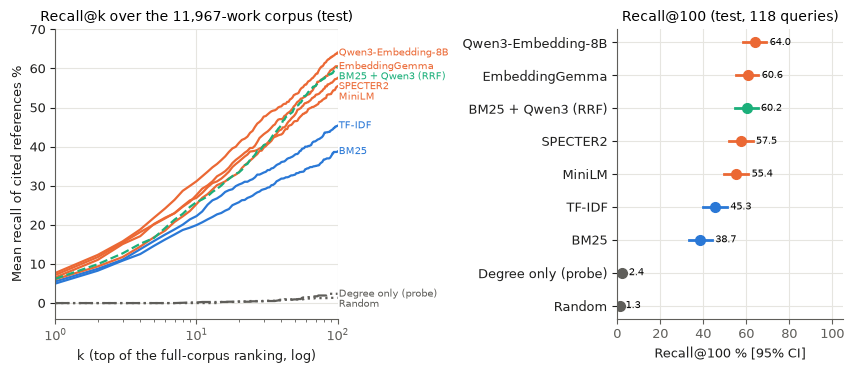

In [11]:
import matplotlib.pyplot as plt

from src.figures import FAMILY_COLOR, INK_2, SLOTS, family, label

NAMES = {"bm25+qwen": "BM25 + Qwen3 (RRF)", "degree": "Degree only (probe)", "random": "Random"}
def style(m):
    if m == "bm25+qwen":
        return SLOTS[2], "--"
    if m in ("degree", "random"):
        return INK_2, ":" if m == "random" else "-."
    return FAMILY_COLOR[family(m)], "-"

ks = np.arange(1, 101)
test_q = [q for q in qids if labels[q]["split"] == "test"]
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
curves = {}
for m in orders:
    ranks = [np.flatnonzero(np.isin(orders[m][q][:100], pos_idx[q])) + 1 for q in test_q]
    curves[m] = np.array([np.mean([(r <= k).sum() / len(pos_idx[q]) for r, q in zip(ranks, test_q)]) for k in ks]) * 100
    color, ls = style(m)
    ax.plot(ks, curves[m], ls, color=color, lw=1.6)
ends = sorted(((curves[m][-1], m) for m in orders), reverse=True)
last_y = None
for y, m in ends:  # direct labels at the right end, nudged apart
    y_lab = y if last_y is None else min(y, last_y - 2.6)
    ax.text(102, y_lab, NAMES.get(m, label(m)), color=style(m)[0], fontsize=7, va="center")
    last_y = y_lab
ax.set_xscale("log")
ax.set_xlim(1, 100)
ax.set_ylim(-4, 70)
ax.set_xlabel("k (top of the full-corpus ranking, log)")
ax.set_ylabel("Mean recall of cited references %")
ax.set_title("Recall@k over the 11,967-work corpus (test)")

ax = axes[1]
order_m = test_tab["method"].tolist()
for i, m in enumerate(order_m):
    row = test_tab.set_index("method").loc[m]
    lo, hi = [float(v) for v in row["recall@100_ci"].strip("[]").split(", ")]
    color = style(m)[0]
    ax.plot([lo, hi], [i, i], color=color, lw=2)
    ax.plot(row["recall@100"], i, "o", color=color)
    ax.text(hi + 1.5, i, f"{row['recall@100']:.1f}", va="center", fontsize=7)
ax.set_yticks(range(len(order_m)), [NAMES.get(m, label(m)) for m in order_m])
ax.invert_yaxis()
ax.set_xlim(0, 105)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Recall@100 % [95% CI]")
ax.set_title("Recall@100 (test, 118 queries)")
fig.tight_layout()
save(fig, "09_full_corpus_recall")
plt.show()

### Headroom for graph expansion

How many test positives fall outside Qwen3's top 100, and how many of those are *reachable* through the graph (some allowed citer cites them, all rules on)? This bounds what co-citation expansion in notebook 10 can add on top of the best first stage.

In [12]:
missed = reachable = 0
for q in test_q:
    top = set(orders["qwen"][q][:100].tolist())
    mask = g.allowed(q, labels[q]["date"], Rules())
    for i in pos_idx[q]:
        if i not in top:
            missed += 1
            reachable += int(g.C[mask][:, i].sum() > 0)
print(f"test positives outside Qwen3's top 100: {missed} of {sum(len(pos_idx[q]) for q in test_q)}; "
      f"reachable through an allowed citer: {reachable} ({reachable / missed:.1%})")

test positives outside Qwen3's top 100: 315 of 855; reachable through an allowed citer: 151 (47.9%)


### Findings

- **Setup.** 166 queries (118 test, 48 dev) are ranked against the 11,967-work corpus. A query has 8,715–11,956 candidates (median 11,269), against at most 42 in v2. 13 corpus records duplicate a query and are excluded for that query only. 21 positives dated on or after their query are kept (decision 4).
- **Headline (test, 118 queries).** Qwen3-Embedding-8B is best:
  - recall@100 **64.0% [58.7, 69.4]**, recall@10 31.1%, nDCG@10 0.340, MRR 0.609, R-precision 25.1%;
  - a random ranking gets 1.3% recall@100 (expected 0.9%).
  - On the fixed v2 pools the same model scored 87.0% R-precision. Full-corpus retrieval is a much harder, more realistic setting, and over a third of the cited references fall outside the top 100.
- **Order** (recall@100, test):

  | Method | Recall@100 |
  |---|---|
  | Qwen3 | 64.0% |
  | EmbeddingGemma | 60.6% |
  | BM25 + Qwen3 (RRF) | 60.2% |
  | SPECTER2 | 57.5% |
  | MiniLM | 55.4% |
  | TF-IDF | 45.3% |
  | BM25 | 38.7% |

  Dense models beat lexical ones by 10–25 points. Dev shows the same pattern (Qwen3 67.4%).
- **Tests** (Holm-corrected paired Wilcoxon).
  - Qwen3 vs EmbeddingGemma: recall@100 does not differ significantly (p_holm = 0.11), but nDCG@10 does (p_holm = 0.019).
  - Qwen3 beats every other method on both metrics (p_holm ≤ 0.05; MiniLM's nDCG@10 is borderline at 0.0499).
  - **Fusing BM25 into Qwen3 hurts**: −3.9 points recall@100, −0.065 nDCG@10. This matches v2, where the hybrid also lost to Qwen3 alone.
- **The membership asymmetry is worth almost nothing.** The degree-only probe reaches 2.4% [1.1, 3.9] recall@100 against 1.3% [0.5, 2.4] for random. Positives were added to the corpus regardless of degree, but that does not make them easy to find by degree.
- **Membership-symmetric positives** (≥ 5 pool citers: 424 of 1,219, in 130 queries). Every dense method finds them more easily: Qwen3 73.4% vs 63.1% on all positives of the same test queries. Well-cited references are easier to retrieve.
- **Headroom for graph expansion.** 315 of the 855 test positives fall outside Qwen3's top 100. 151 of those (47.9%) are reachable through an allowed citer, which is the most co-citation expansion could recover (notebook 10).
- **Figure.** `09_full_corpus_recall`. Runs are in `v2/runs_corpus/stage1/`.
